In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt


In [2]:
# Read CSV files
pax = pd.read_csv("pax_configuration.csv", sep=";", decimal=",")
cargo = pd.read_csv("cargo_values.csv", sep=";", decimal=",")
fuel = pd.read_csv("FuelTanks.csv", sep=";", decimal=",")

# Show tables
display(pax)
display(cargo)
display(fuel)



,section,Arm,Maxseats,Paxweight
0,1,351.25,35,NaN
1,2,867.25,130,NaN
2,3,1445.75,140,NaN
3,4,1971.50,120,NaN


,Section,Balancearm,Maxweight,Weight
0,1,358.575000,6350.28,NaN
1,2,738.987500,13448.99,NaN
2,3,1631.783333,10273.85,NaN
3,4,1941.425000,6350.28,NaN
4,5,2163.000000,4082.00,NaN


,Tank,Balancearm,Maxweight,Weight
0,Main1,1321.3,33171.0,NaN
1,Main2,1321.3,33171.0,NaN
2,Center,1146.4,87887.0,NaN


In [3]:
# Aircraft basic data
DOW = 171000
DOW_CG = 30.0  # Assumed %MAC

# Aircraft weight limits (kg)
MZFW = 237682
MTOW = 351534
MLW = 251290

# Mean Aerodynamic Chord
MAC = 278.5
LEMAC = 1174.5

# Convert DOW CG from %MAC to balance arm
DOW_BA = LEMAC + (DOW_CG / 100) * MAC

# Calculate initial aircraft moment
DOW_moment = DOW * DOW_BA

print("DOW:", DOW, "kg")
print("DOW CG:", DOW_CG, "%MAC")
print("DOW Balance Arm:", round(DOW_BA, 2), "inches")
print("DOW Moment:", round(DOW_moment, 2), "kg.in")


DOW: 171000 kg
DOW CG: 30.0 %MAC
DOW Balance Arm: 1258.05 inches
DOW Moment: 215126550.0 kg.in


In [4]:
# Function to calculate the centre of gravity
def calculate_cg(weights, arms):
    total_weight = sum(weights)
    total_moment = sum(w * a for w, a in zip(weights, arms))

    cg_arm = total_moment / total_weight
    cg_mac = ((cg_arm - LEMAC) / MAC) * 100

    return total_weight, total_moment, cg_arm, cg_mac


In [6]:
# Example: loading 2000 kg in cargo section 1

cargo_weight = 2000
cargo_arm = 358.575

weights = [DOW, cargo_weight]
arms = [DOW_BA, cargo_arm]

total_weight, total_moment, cg_arm, cg_mac = calculate_cg(weights, arms)

print("Total weight:", round(total_weight, 2), "kg")
print("Total moment:", round(total_moment, 2), "kg.in")
print("CG balance arm:", round(cg_arm, 2), "inches")
print("CG:", round(cg_mac, 2), "%MAC")


Total weight: 173000 kg
Total moment: 215843700.0 kg.in
CG balance arm: 1247.65 inches
CG: 26.27 %MAC


In [11]:
# Example cargo weights for each section
cargo_weights = [2000, 3000, 1500, 1000, 1000]

# Read balance arms from the CSV
cargo_arms = cargo["Balancearm"].tolist()

# Check maximum cargo weights
for i in range(len(cargo_weights)):
    if cargo_weights[i] > cargo["Maxweight"].iloc[i]:
        print("Cargo section", i + 1, "is overloaded!")

# Include aircraft dry operating weight
weights = [DOW] + cargo_weights
arms = [DOW_BA] + cargo_arms

# Calculate total weight and CG
total_weight, total_moment, cg_arm, cg_mac = calculate_cg(weights, arms)

print("Total weight:", round(total_weight, 2), "kg")
print("CG balance arm:", round(cg_arm, 2), "inches")
print("CG:", round(cg_mac, 2), "%MAC")


Total weight: 179500 kg
CG balance arm: 1251.32 inches
CG: 27.59 %MAC


In [13]:
# Example number of passengers per section
pax_numbers = [25, 90, 100, 85]

# Assumed average passenger weight (kg)
pax_weight = 84

# Calculate passenger weight per section
pax_weights = [number * pax_weight for number in pax_numbers]

# Read balance arms from CSV
pax_arms = pax["Arm"].tolist()

# Check maximum seats per section
for i in range(len(pax_numbers)):
    if pax_numbers[i] > pax["Maxseats"].iloc[i]:
        print("WARNING: Passenger section", i + 1, "is overloaded!")

# Combine aircraft, cargo and passengers
weights = [DOW] + cargo_weights + pax_weights
arms = [DOW_BA] + cargo_arms + pax_arms

# Calculate Zero Fuel Weight and CG
ZFW, ZFW_moment, ZFW_arm, ZFW_mac = calculate_cg(weights, arms)

print("Total passengers:", sum(pax_numbers))
print("Passenger weight:", sum(pax_weights), "kg")
print("Zero Fuel Weight:", round(ZFW, 2), "kg")
print("ZFW CG:", round(ZFW_mac, 2), "%MAC")

# Check maximum zero fuel weight
if ZFW > MZFW:
    print("WARNING: Maximum Zero Fuel Weight exceeded!")
else:
    print("Zero Fuel Weight is within the weight limit.")


Total passengers: 300
Passenger weight: 25200 kg
Zero Fuel Weight: 204700 kg
ZFW CG: 31.06 %MAC
Zero Fuel Weight is within the weight limit.


In [15]:
# Example fuel quantities (kg)
fuel_weights = [20000, 20000, 30000]

# Read fuel balance arms from CSV
fuel_arms = fuel["Balancearm"].tolist()

# Calculate total fuel weight and moment
total_fuel = sum(fuel_weights)
fuel_moment = sum(w * a for w, a in zip(fuel_weights, fuel_arms))

# Calculate Take-off Weight and CG
TOW = ZFW + total_fuel
TOW_moment = ZFW_moment + fuel_moment

TOW_arm = TOW_moment / TOW
TOW_mac = ((TOW_arm - LEMAC) / MAC) * 100

print("Total fuel:", total_fuel, "kg")
print("Take-off Weight:", round(TOW, 2), "kg")
print("Take-off CG:", round(TOW_mac, 2), "%MAC")

# Check maximum take-off weight
if TOW > MTOW:
    print("WARNING: Maximum Take-off Weight exceeded!")
else:
    print("Take-off Weight is within the weight limit.")


Total fuel: 70000 kg
Take-off Weight: 274700 kg
Take-off CG: 29.72 %MAC
Take-off Weight is within the weight limit.


In [17]:
# Example fuel remaining at landing (kg)
landing_fuel = [5000, 5000, 3000]

# Calculate remaining fuel weight and moment
total_landing_fuel = sum(landing_fuel)

landing_fuel_moment = sum(
    w * a for w, a in zip(landing_fuel, fuel_arms)
)

# Calculate Landing Weight and CG
LW = ZFW + total_landing_fuel
LW_moment = ZFW_moment + landing_fuel_moment

LW_arm = LW_moment / LW
LW_mac = ((LW_arm - LEMAC) / MAC) * 100

print("Landing fuel:", total_landing_fuel, "kg")
print("Landing Weight:", round(LW, 2), "kg")
print("Landing CG:", round(LW_mac, 2), "%MAC")

# Check maximum landing weight
if LW > MLW:
    print("WARNING: Maximum Landing Weight exceeded!")
else:
    print("Landing Weight is within the weight limit.")


Landing fuel: 13000 kg
Landing Weight: 217700 kg
Landing CG: 31.49 %MAC
Landing Weight is within the weight limit.


In [19]:
print("BOEING 777-300ER WEIGHT AND BALANCE")
print("----------------------------------")

print("ZFW:", round(ZFW), "kg | CG:", round(ZFW_mac, 2), "%MAC")
print("TOW:", round(TOW), "kg | CG:", round(TOW_mac, 2), "%MAC")
print("LW: ", round(LW), "kg | CG:", round(LW_mac, 2), "%MAC")


BOEING 777-300ER WEIGHT AND BALANCE
----------------------------------
ZFW: 204700 kg | CG: 31.06 %MAC
TOW: 274700 kg | CG: 29.72 %MAC
LW:  217700 kg | CG: 31.49 %MAC


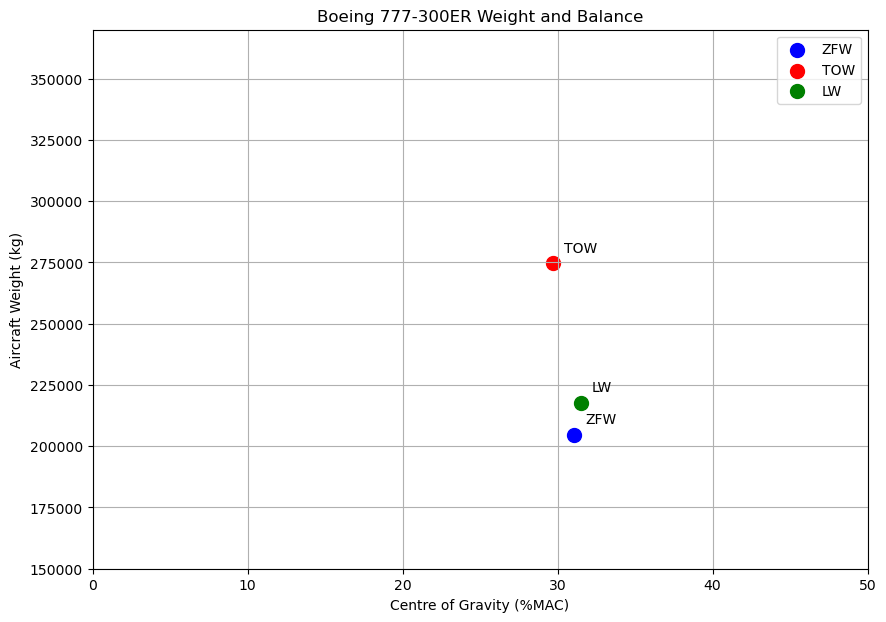

In [21]:
# Aircraft weights and CG positions
weights = [ZFW, TOW, LW]
cg_values = [ZFW_mac, TOW_mac, LW_mac]

labels = ["ZFW", "TOW", "LW"]
colors = ["blue", "red", "green"]

plt.figure(figsize=(10, 7))

# Plot each flight condition
for i in range(3):
    plt.scatter(cg_values[i], weights[i],
                color=colors[i], s=100, label=labels[i])

    plt.annotate(labels[i],
                 (cg_values[i], weights[i]),
                 xytext=(8, 8),
                 textcoords="offset points")

plt.xlabel("Centre of Gravity (%MAC)")
plt.ylabel("Aircraft Weight (kg)")
plt.title("Boeing 777-300ER Weight and Balance")
plt.grid(True)
plt.legend()

plt.xlim(0, 50)
plt.ylim(150000, 370000)

plt.show()


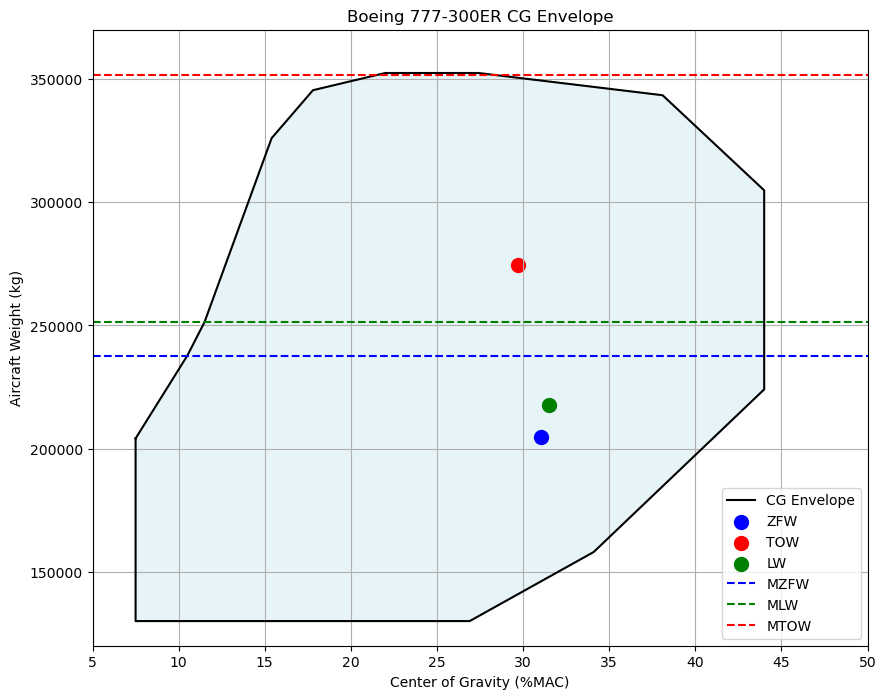

In [23]:
# Certified CG envelope coordinates
# X = CG (%MAC), Y = aircraft weight (kg)

cg_envelope = [
    (7.5, 204116),
    (10.5, 237682),
    (11.5, 251290),
    (15.4, 325996),
    (17.8, 345455),
    (22.0, 352441),
    (27.4, 352441),
    (38.1, 343414),
    (44.0, 304814),
    (44.0, 279911),
    (44.0, 224029),
    (34.1, 158031),
    (26.9, 130000),
    (7.5, 130000),
    (7.5, 204116)
]

# Separate X and Y coordinates
cg_x = [point[0] for point in cg_envelope]
cg_y = [point[1] for point in cg_envelope]

plt.figure(figsize=(10, 8))

# Plot CG envelope
plt.plot(cg_x, cg_y, color="black", label="CG Envelope")
plt.fill(cg_x, cg_y, color="lightblue", alpha=0.3)

# Plot aircraft loading conditions
plt.scatter(ZFW_mac, ZFW, color="blue", s=100, label="ZFW")
plt.scatter(TOW_mac, TOW, color="red", s=100, label="TOW")
plt.scatter(LW_mac, LW, color="green", s=100, label="LW")

# Weight limits
plt.axhline(MZFW, color="blue", linestyle="--", label="MZFW")
plt.axhline(MLW, color="green", linestyle="--", label="MLW")
plt.axhline(MTOW, color="red", linestyle="--", label="MTOW")

plt.xlabel("Center of Gravity (%MAC)")
plt.ylabel("Aircraft Weight (kg)")
plt.title("Boeing 777-300ER CG Envelope")

plt.xlim(5, 50)
plt.ylim(120000, 370000)

plt.grid(True)
plt.legend()
plt.show()


In [25]:
from matplotlib.path import Path

# Create the CG envelope
envelope = Path(cg_envelope)

# Function to check weight and CG
def check_limits(weight, cg, max_weight):
    weight_ok = weight <= max_weight
    cg_ok = envelope.contains_point((cg, weight))

    if weight_ok and cg_ok:
        return "WITHIN LIMITS"
    else:
        return "OUTSIDE LIMITS"

# Check each flight condition
ZFW_status = check_limits(ZFW, ZFW_mac, MZFW)
TOW_status = check_limits(TOW, TOW_mac, MTOW)
LW_status = check_limits(LW, LW_mac, MLW)

print("BOEING 777-300ER LOADING CHECK")
print("--------------------------------")

print("ZFW:", ZFW_status)
print("TOW:", TOW_status)
print("LW: ", LW_status)


BOEING 777-300ER LOADING CHECK
--------------------------------
ZFW: WITHIN LIMITS
TOW: WITHIN LIMITS
LW:  WITHIN LIMITS


In [27]:
results = pd.DataFrame({
    "Condition": ["ZFW", "TOW", "LW"],
    "Weight (kg)": [ZFW, TOW, LW],
    "CG (%MAC)": [ZFW_mac, TOW_mac, LW_mac],
    "Status": [ZFW_status, TOW_status, LW_status]
})

display(results.round(2))


,Condition,Weight (kg),CG (%MAC),Status
0,ZFW,204700,31.06,WITHIN LIMITS
1,TOW,274700,29.72,WITHIN LIMITS
2,LW,217700,31.49,WITHIN LIMITS


In [29]:
import ipywidgets as widgets
from IPython.display import display


In [49]:
# Passenger sliders
pax_sliders = [
    widgets.IntSlider(
        value=0,
        min=0,
        max=int(pax["Maxseats"].iloc[i]),
        description=f"PAX section {i+1}",
        style={"description_width": "150px"}
    )
    for i in range(4)
]

# Cargo sliders
cargo_sliders = [
    widgets.FloatSlider(
        value=0,
        min=0,
        max=float(cargo["Maxweight"].iloc[i]),
        step=100,
        description=["Cargo fwd 1", "Cargo fwd 2", "Cargo aft 1", "Cargo aft 2", "Bulk Cargo"][i],
        style={"description_width": "150px"}
    )
    for i in range(len(cargo))
]

# Fuel sliders
fuel_sliders = [
    widgets.FloatSlider(
        value=0,
        min=0,
        max=float(fuel["Maxweight"].iloc[i]),
        step=500,
        description=["Main Tank 1", "Main Tank 2", "Center Tank"][i],
        style={"description_width": "150px"}
    )
    for i in range(3)
]

display(widgets.VBox([
    widgets.HTML("<h3>Passenger Loading</h3>"),
    *pax_sliders,
    widgets.HTML("<h3>Cargo Loading</h3>"),
    *cargo_sliders,
    widgets.HTML("<h3>Fuel Loading</h3>"),
    *fuel_sliders
]))


In [51]:
# Read current passenger numbers
pax_numbers = [slider.value for slider in pax_sliders]
pax_weights = [number * pax_weight for number in pax_numbers]

# Read current cargo and fuel quantities
cargo_weights = [slider.value for slider in cargo_sliders]
fuel_weights = [slider.value for slider in fuel_sliders]

print("Passengers:", sum(pax_numbers))
print("Cargo:", round(sum(cargo_weights)), "kg")
print("Fuel:", round(sum(fuel_weights)), "kg")


Passengers: 0
Cargo: 0 kg
Fuel: 0 kg


In [53]:
import ipywidgets as widgets
from IPython.display import display
import pandas as pd
import matplotlib.pyplot as plt

# BOEING 777-300ER VISUAL LOADING SYSTEM
# Trip fuel slider
trip_fuel_slider = widgets.FloatSlider(
    value=0,
    min=0,
    max=1,
    step=100,
    description="Trip Fuel",
    style={"description_width": "100px"},
    continuous_update=False
)

# Function to calculate and display the dashboard
def update_dashboard(**kwargs):

# READ SLIDER VALUES
    pax_numbers = [s.value for s in pax_sliders]
    cargo_weights = [s.value for s in cargo_sliders]
    fuel_weights = [s.value for s in fuel_sliders]

    # Total fuel at take-off
    total_fuel = sum(fuel_weights)

    # Trip fuel cannot exceed take-off fuel
    trip_fuel = min(trip_fuel_slider.value, total_fuel)


# CALCULATE LANDING FUEL
    # Simplified model:
    # Burn center tank first, then main tanks equally

    landing_fuel = fuel_weights.copy()
    fuel_to_burn = trip_fuel

    # Burn center tank
    burn = min(landing_fuel[2], fuel_to_burn)
    landing_fuel[2] -= burn
    fuel_to_burn -= burn

    # Burn main tanks
    while fuel_to_burn > 0.001:

        available = [
            i for i in (0, 1)
            if landing_fuel[i] > 0.001
        ]

        if not available:
            break

        share = fuel_to_burn / len(available)

        for i in available:
            burn = min(landing_fuel[i], share)
            landing_fuel[i] -= burn
            fuel_to_burn -= burn


# CALCULATE PASSENGER WEIGHTS
    pax_weights = [
        number * pax_weight
        for number in pax_numbers
    ]


# CALCULATE ZFW, TOW AND LW
    # Zero Fuel Weight
    weights = [DOW] + cargo_weights + pax_weights
    arms = [DOW_BA] + cargo_arms + pax_arms

    ZFW, ZFW_moment, ZFW_arm, ZFW_mac = calculate_cg(
        weights, arms
    )

    # Take-off Weight
    TOW, TOW_moment, TOW_arm, TOW_mac = calculate_cg(
        weights + fuel_weights,
        arms + fuel_arms
    )

    # Landing Weight
    LW, LW_moment, LW_arm, LW_mac = calculate_cg(
        weights + landing_fuel,
        arms + fuel_arms
    )


# CHECK WEIGHT AND CG LIMITS
    ZFW_status = check_limits(ZFW, ZFW_mac, MZFW)
    TOW_status = check_limits(TOW, TOW_mac, MTOW)
    LW_status = check_limits(LW, LW_mac, MLW)

# DISPLAY FUEL INFORMATION
    print("Take-off fuel:", round(total_fuel), "kg")
    print("Trip fuel:", round(trip_fuel), "kg")
    print("Landing fuel:", round(sum(landing_fuel)), "kg")

# DISPLAY RESULTS TABLE
    results = pd.DataFrame({
        "Condition": ["ZFW", "TOW", "LW"],
        "Weight (kg)": [ZFW, TOW, LW],
        "CG (%MAC)": [ZFW_mac, TOW_mac, LW_mac],
        "Status": [ZFW_status, TOW_status, LW_status]
    })

    display(results.round(2))

# CREATE CG ENVELOPE GRAPH
    plt.figure(figsize=(12, 9))

    # CG envelope boundary
    plt.plot(
        cg_x, cg_y,
        color="black",
        linewidth=1.5
    )

    plt.fill(
        cg_x, cg_y,
        color="lightblue",
        alpha=0.2
    )

# GREY RESTRICTED TAKE-OFF AREA
    # Approximate shaded area from reference diagram
    grey_x = [34.1, 44.0, 44.0]
    grey_y = [158031, 224029, 279911]

    plt.fill(
        grey_x,
        grey_y,
        color="grey",
        alpha=0.4,
        label="Restricted take-off area"
    )

    # Restricted area warning
    plt.text(
        36, 216000,
        "Do not operate\nin shaded area\nduring takeoff",
        fontsize=8,
        ha="center"
    )

# MAXIMUM WEIGHT LABELS
    plt.text(
        12, 361000,
        "MAXIMUM TAXI\nWEIGHT: 352441 KG",
        fontsize=8,
        fontweight="bold"
    )

    plt.text(
        31, 361000,
        "MAXIMUM TAKEOFF\nWEIGHT: 351534 KG",
        fontsize=8,
        fontweight="bold"
    )

    plt.text(
        29, 253000,
        "MAXIMUM LANDING\nWEIGHT: 251290 KG",
        fontsize=8,
        fontweight="bold"
    )

    plt.text(
        29, 239000,
        "MAXIMUM ZERO FUEL\nWEIGHT: 237682 KG",
        fontsize=8,
        fontweight="bold"
    )

# TAKE-OFF CG REFERENCE LINES
    plt.vlines(
        [24, 27],
        ymin=130000,
        ymax=351534,
        colors="black",
        linewidth=0.8
    )

    plt.text(
        23.2, 140000,
        "Alternate Forward C.G. Limit for Takeoff I 24%",
        rotation=90,
        fontsize=8
    )

    plt.text(
        26.2, 140000,
        "Alternate Forward C.G. Limit for Takeoff II 27%",
        rotation=90,
        fontsize=8
    )

# ENVELOPE BOUNDARY ANNOTATIONS
    plt.annotate(
        "11.5%",
        xy=(11.5, 251290),
        xytext=(11.0, 258000),
        fontsize=8,
        ha="right",
        arrowprops=dict(arrowstyle="-", color="black", lw=0.5)
    )

    plt.annotate(
        "10.5%",
        xy=(10.5, 237682),
        xytext=(10.0, 245000),
        fontsize=8,
        ha="right",
        arrowprops=dict(arrowstyle="-", color="black", lw=0.5)
    )
    plt.annotate(
        "22.0%",
        xy=(22.0, 351534),
        xytext=(22.0, 357000),
        fontsize=8,
        ha="center",
        arrowprops=dict(arrowstyle="-", color="black", lw=0.5)
    )


    plt.annotate(
        "27.4%",
        xy=(27.4, 351534),
        xytext=(27.4, 357000),
        fontsize=8,
        ha="center",
        arrowprops=dict(arrowstyle="-", color="black", lw=0.5)
    )


    plt.annotate(
        "26.9%",
        xy=(26.9, 130000),
        xytext=(26.5, 135000),
        fontsize=8,
        ha="right",
        arrowprops=dict(arrowstyle="-", color="black", lw=0.5)
    )
    
    plt.annotate(
        "204116 KG at 7.5%",
        xy=(7.5, 204116),
        xytext=(9, 208000),
        fontsize=8,
        va="center",
        arrowprops=dict(arrowstyle="-", color="black", lw=0.5)
    )
    plt.annotate(
        "325996 KG\nat 15.4%",
        xy=(15.4, 325996),
        xytext=(14.4, 325996),
        fontsize=8,
        ha="right",
        va="center",
        arrowprops=dict(arrowstyle="-", color="black", lw=0.5)
    )
    
    plt.annotate(
        "345455 KG\nat 17.8%",
        xy=(17.8, 345455),
        xytext=(17, 345455),
        fontsize=8,
        ha="right",
        va="center",
        arrowprops=dict(arrowstyle="-", color="black", lw=0.5)
    )

    plt.annotate(
        "343414 KG\nat 38.1%",
        xy=(38.1, 343414),
        xytext=(39.2, 343414),
        fontsize=8,
        ha="left",
        va="center",
        arrowprops=dict(arrowstyle="-", color="black", lw=0.5)
    )

    plt.annotate(
        "279911 KG\nat 44.0%",
        xy=(44, 279911),
        xytext=(45.5, 279911),
        fontsize=8,
        ha="left",
        va="center",
        arrowprops=dict(arrowstyle="-", color="black", lw=0.5)
    )
    
    plt.annotate(
        "224029 KG\nat 44.0%",
        xy=(44, 224029),
        xytext=(45.5, 224029),
        fontsize=8,
        ha="left",
        va="center",
        arrowprops=dict(arrowstyle="-", color="black", lw=0.5)
    )

    plt.annotate(
        "158031 KG\nat 34.1%",
        xy=(34.1, 158031),
        xytext=(35, 155000),
        fontsize=8,
        ha="left",
        va="center",
        arrowprops=dict(arrowstyle="-", color="black", lw=0.5)
    )
        
    plt.annotate(
        "304814 KG\nat 44.0% at",
        xy=(44, 304814),
        xytext=(45, 310000),
        fontsize=8,
        ha="left",
        va="center",
        arrowprops=dict(arrowstyle="-", color="black", lw=0.5)
    )

# PLOT AIRCRAFT CG POINTS
    # Zero Fuel Weight
    plt.scatter(
        ZFW_mac, ZFW,
        color="blue",
        marker="o",
        s=130,
        label="ZFW",
        zorder=5
    )

    # Take-off Weight
    plt.scatter(
        TOW_mac, TOW,
        color="red",
        marker="o",
        s=130,
        label="TOW",
        zorder=5
    )

    # Landing Weight
    plt.scatter(
        LW_mac, LW,
        color="green",
        marker="o",
        s=130,
        label="LW",
        zorder=5
    )

# MAXIMUM WEIGHT LIMIT LINES
    plt.axhline(
        MZFW,
        color="blue",
        linestyle="--",
        alpha=0.5
    )

    plt.axhline(
        MLW,
        color="green",
        linestyle="--",
        alpha=0.5
    )

    plt.axhline(
        MTOW,
        color="red",
        linestyle="--",
        alpha=0.5
    )

# GRAPH SETTINGS
    plt.xlabel("CENTER OF GRAVITY - % MAC")
    plt.ylabel("GROSS WEIGHT - KG")

    plt.title(
        "Boeing 777-300ER Visual Loading System",
        fontsize=14,
        fontweight="bold"
    )

    plt.xlim(5, 50)
    plt.ylim(120000, 375000)

    plt.xticks(range(5,51,5))
    plt.yticks(range(120000,375001,10000))

    plt.minorticks_on()
    plt.grid(True, alpha=0.3)
    plt.legend(loc="lower right")

    plt.show()

# CONNECT ALL SLIDERS
controls = {}

# Passenger sliders
for i, slider in enumerate(pax_sliders):
    controls[f"pax_{i}"] = slider

# Cargo sliders
for i, slider in enumerate(cargo_sliders):
    controls[f"cargo_{i}"] = slider

# Take-off fuel sliders
for i, slider in enumerate(fuel_sliders):
    controls[f"fuel_{i}"] = slider

# Trip fuel slider
controls["trip_fuel"] = trip_fuel_slider

# AUTOMATIC TRIP FUEL LIMIT
def update_trip_fuel_limit(change=None):

    total = sum(s.value for s in fuel_sliders)

    # Maximum trip fuel equals loaded take-off fuel
    trip_fuel_slider.max = max(1, total)


for slider in fuel_sliders:
    slider.observe(
        update_trip_fuel_limit,
        names="value"
    )

update_trip_fuel_limit()

# CREATE INTERACTIVE DASHBOARD
dashboard_output = widgets.interactive_output(
    update_dashboard,
    controls
)

# DISPLAY COMPLETE DASHBOARD

display(widgets.VBox([

    widgets.HTML(
        "<h2>Boeing 777-300ER Visual Loading System</h2>"
    ),

    widgets.HTML("<h3>Passenger Loading</h3>"),
    *pax_sliders,

    widgets.HTML("<h3>Cargo Loading</h3>"),
    *cargo_sliders,

    widgets.HTML("<h3>Take-off Fuel</h3>"),
    *fuel_sliders,

    widgets.HTML("<h3>Trip Fuel</h3>"),
    trip_fuel_slider,

    widgets.HTML("<h3>Weight and Balance Results</h3>"),
    dashboard_output

]))
